# Boundary-Violation and Trajectory Analysis

This notebook investigates the 1,081 ground-truth observations found outside the official room domain `[0, 4.8] x [0, 7.2]` m. It determines whether violations are isolated annotation spikes or continuous trajectory segments and defines the preprocessing policy used for training.

## 1. Setup and authentication

The notebook reuses files already stored in the Hugging Face cache. If `HF_TOKEN` is not available to the kernel, it requests the token through a hidden input field.

In [1]:
%matplotlib inline

import getpass
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import HfApi, hf_hub_download

ROOM_X_METERS = 4.8
ROOM_Y_METERS = 7.2
MAX_PEOPLE = 4
SAMPLING_RATE_HZ = 25.0
REPO_ID = 'HAEEAI/multi-person-localization'
TOTAL_WINDOWS = 24

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
if not HF_TOKEN:
    raise RuntimeError('A Hugging Face token is required.')

api = HfApi(token=HF_TOKEN)
print('Authenticated as:', api.whoami()['name'])

C:\Users\213053\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti


## 2. Load ground truth from all acquisition windows

Only `people_xy` and `people_mask` are retained. The large radar tensors are not copied, so this analysis requires far less memory than the full EDA.

In [2]:
windows = {}
for window_index in range(TOTAL_WINDOWS):
    filename = f'data/window_{window_index:06d}.npz'
    cached_path = hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, token=HF_TOKEN
    )
    with np.load(cached_path, allow_pickle=False) as data:
        xy = np.asarray(data['people_xy'], dtype=np.float32)
        mask = np.asarray(data['people_mask']).astype(bool)
    windows[f'window_{window_index:06d}'] = {'xy': xy, 'mask': mask}
    print(f'[{window_index + 1:02d}/{TOTAL_WINDOWS:02d}] Ready: {filename}')

[01/24] Ready: data/window_000000.npz
[02/24] Ready: data/window_000001.npz
[03/24] Ready: data/window_000002.npz
[04/24] Ready: data/window_000003.npz
[05/24] Ready: data/window_000004.npz
[06/24] Ready: data/window_000005.npz
[07/24] Ready: data/window_000006.npz
[08/24] Ready: data/window_000007.npz
[09/24] Ready: data/window_000008.npz
[10/24] Ready: data/window_000009.npz
[11/24] Ready: data/window_000010.npz
[12/24] Ready: data/window_000011.npz
[13/24] Ready: data/window_000012.npz
[14/24] Ready: data/window_000013.npz
[15/24] Ready: data/window_000014.npz
[16/24] Ready: data/window_000015.npz
[17/24] Ready: data/window_000016.npz
[18/24] Ready: data/window_000017.npz
[19/24] Ready: data/window_000018.npz
[20/24] Ready: data/window_000019.npz
[21/24] Ready: data/window_000020.npz
[22/24] Ready: data/window_000021.npz
[23/24] Ready: data/window_000022.npz
[24/24] Ready: data/window_000023.npz


## 3. Identify violations and contiguous temporal segments

A contiguous segment is a sequence of consecutive frames in which the same target slot remains outside the official room boundary. Long segments are more consistent with entrance/exit trajectories than with isolated label noise.

In [3]:
def contiguous_runs(frame_indices):
    if len(frame_indices) == 0:
        return []
    split_points = np.where(np.diff(frame_indices) > 1)[0] + 1
    groups = np.split(frame_indices, split_points)
    return [(int(group[0]), int(group[-1]), int(len(group))) for group in groups]

trajectory_data = {}
violation_runs = []
total_valid_observations = 0

for window_name, arrays in windows.items():
    xy, mask = arrays['xy'], arrays['mask']
    total_valid_observations += int(mask.sum())
    invalid = mask & (
        (xy[..., 0] < 0.0) | (xy[..., 0] > ROOM_X_METERS) |
        (xy[..., 1] < 0.0) | (xy[..., 1] > ROOM_Y_METERS)
    )
    if not invalid.any():
        continue
    trajectory_data[window_name] = (xy, mask, invalid)
    for slot in range(MAX_PEOPLE):
        for start, end, length in contiguous_runs(np.flatnonzero(invalid[:, slot])):
            violation_runs.append({
                'window': window_name, 'slot': slot, 'start': start, 'end': end,
                'frames': length, 'duration_s': length / SAMPLING_RATE_HZ,
            })

run_lengths = np.array([run['frames'] for run in violation_runs], dtype=np.int64)
total_violations = sum(int(invalid.sum()) for _, _, invalid in trajectory_data.values())
print(f'Out-of-bounds observations: {total_violations:,}')
print(f'Fraction of valid observations: {100 * total_violations / total_valid_observations:.4f}%')
print(f'Affected windows: {len(trajectory_data)}/{TOTAL_WINDOWS}')
print(f'Contiguous violation segments: {len(violation_runs):,}')
print(f'Single-frame segments: {np.sum(run_lengths == 1):,}')
print(f'Segments lasting at least 1 second: {np.sum(run_lengths >= 25):,}')
print(f'Median segment duration: {np.median(run_lengths) / SAMPLING_RATE_HZ:.2f} s')
print(f'Maximum segment duration: {run_lengths.max() / SAMPLING_RATE_HZ:.2f} s')

print('\nTen longest violation segments:')
for run in sorted(violation_runs, key=lambda item: item['frames'], reverse=True)[:10]:
    print(
        f"  {run['window']} | slot {run['slot']} | frames {run['start']}-{run['end']} "
        f"| {run['duration_s']:.2f} s"
    )

Out-of-bounds observations: 1,081
Fraction of valid observations: 0.2574%
Affected windows: 7/24
Contiguous violation segments: 16
Single-frame segments: 0
Segments lasting at least 1 second: 10
Median segment duration: 1.32 s
Maximum segment duration: 9.40 s

Ten longest violation segments:
  window_000005 | slot 3 | frames 2755-2989 | 9.40 s
  window_000008 | slot 0 | frames 446-676 | 9.24 s
  window_000005 | slot 3 | frames 3591-3740 | 6.00 s
  window_000005 | slot 0 | frames 2860-2982 | 4.92 s
  window_000005 | slot 3 | frames 3029-3086 | 2.32 s
  window_000001 | slot 1 | frames 5057-5109 | 2.12 s
  window_000007 | slot 3 | frames 1198-1237 | 1.60 s
  window_000000 | slot 0 | frames 227-260 | 1.36 s
  window_000002 | slot 1 | frames 4642-4673 | 1.28 s
  window_000002 | slot 1 | frames 2963-2993 | 1.24 s


## 4. Visualise affected trajectories

Blue points are valid observations inside the room, while red points are outside the official evaluation domain. Continuous red paths near a boundary indicate entrance/exit motion rather than random annotation spikes.

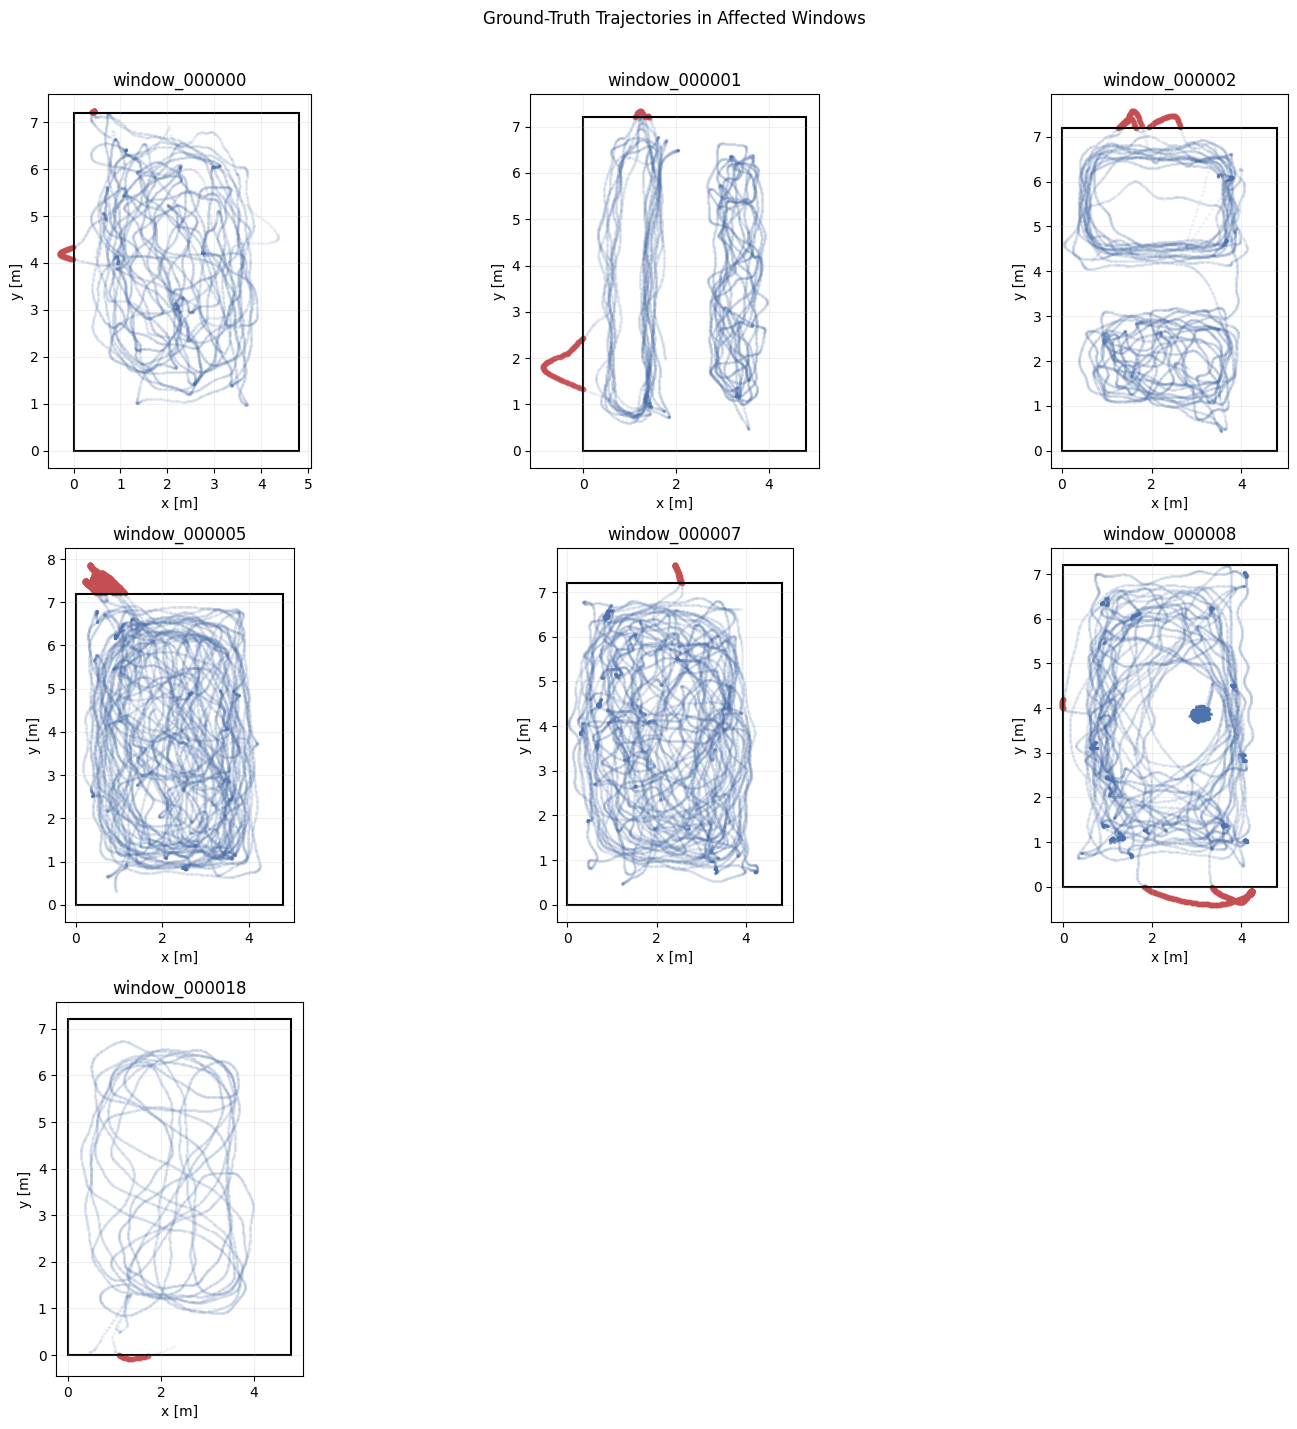

In [4]:
affected_names = list(trajectory_data)
n_columns = 3
n_rows = int(np.ceil(len(affected_names) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 4.7 * n_rows), squeeze=False)

for axis, window_name in zip(axes.flat, affected_names):
    xy, mask, invalid = trajectory_data[window_name]
    inside = mask & ~invalid
    axis.scatter(xy[..., 0][inside], xy[..., 1][inside], s=2, alpha=0.06, color='#4c72b0', label='Inside')
    axis.scatter(xy[..., 0][invalid], xy[..., 1][invalid], s=10, alpha=0.75, color='#c44e52', label='Outside')
    axis.add_patch(plt.Rectangle((0, 0), ROOM_X_METERS, ROOM_Y_METERS, fill=False, color='black', lw=1.5))
    axis.set(title=window_name, xlabel='x [m]', ylabel='y [m]', aspect='equal')
    axis.grid(alpha=0.2)

for axis in axes.flat[len(affected_names):]:
    axis.set_visible(False)
fig.suptitle('Ground-Truth Trajectories in Affected Windows', y=1.01)
plt.tight_layout()
plt.show()

## 5. Inspect the longest segments in temporal context

The plots below show each long segment together with five seconds of context before and after it. This makes it possible to verify whether the person moves smoothly across the boundary.

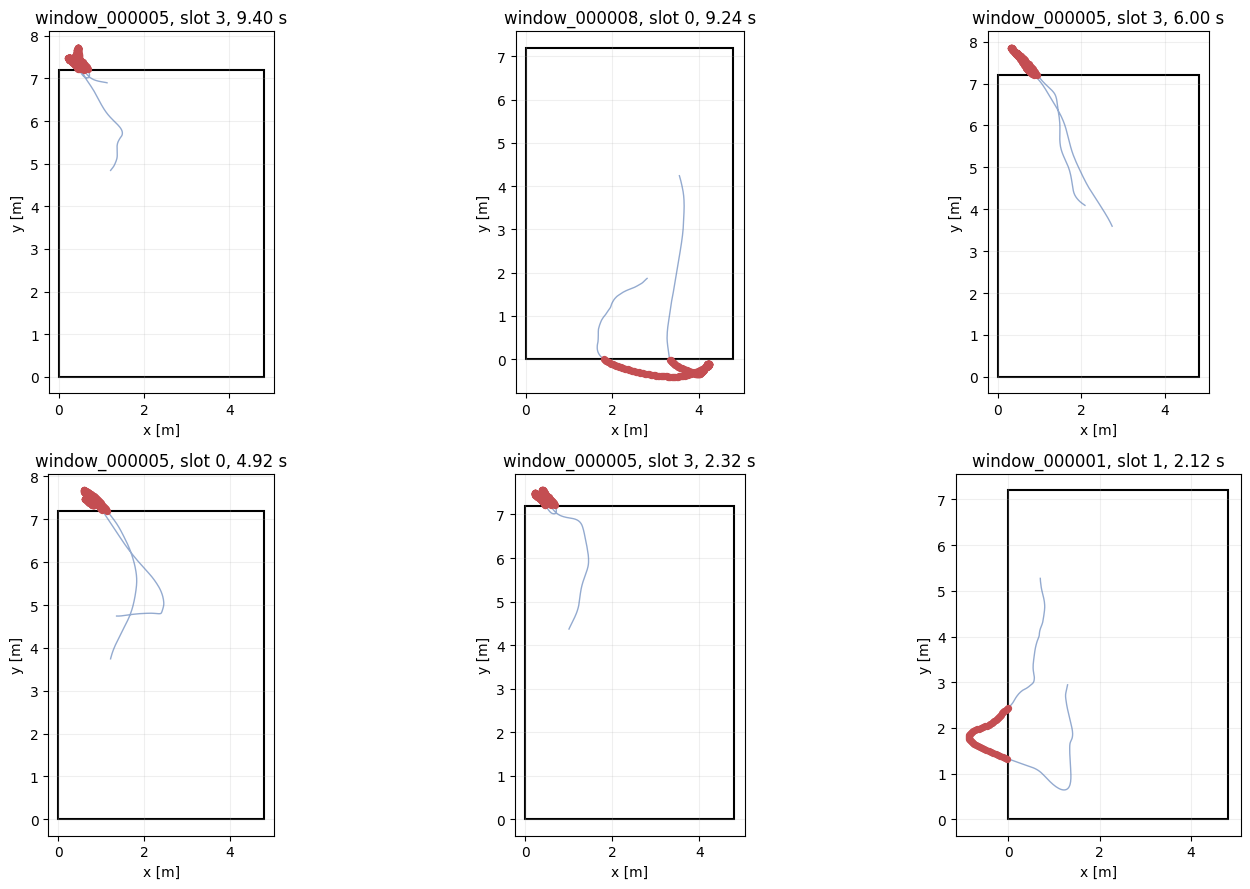

In [5]:
longest_runs = sorted(violation_runs, key=lambda item: item['frames'], reverse=True)[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), squeeze=False)
context_frames = int(5 * SAMPLING_RATE_HZ)

for axis, run in zip(axes.flat, longest_runs):
    xy, mask, invalid = trajectory_data[run['window']]
    slot = run['slot']
    start = max(0, run['start'] - context_frames)
    end = min(len(xy), run['end'] + context_frames + 1)
    local_xy = xy[start:end, slot]
    local_valid = mask[start:end, slot]
    local_invalid = invalid[start:end, slot]
    axis.plot(local_xy[local_valid, 0], local_xy[local_valid, 1], color='#4c72b0', alpha=0.6, lw=1)
    axis.scatter(local_xy[local_invalid, 0], local_xy[local_invalid, 1], color='#c44e52', s=18, zorder=3)
    axis.add_patch(plt.Rectangle((0, 0), ROOM_X_METERS, ROOM_Y_METERS, fill=False, color='black', lw=1.5))
    axis.set(
        title=f"{run['window']}, slot {slot}, {run['duration_s']:.2f} s",
        xlabel='x [m]', ylabel='y [m]', aspect='equal',
    )
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Training preprocessing policy

The recommended baseline policy is to preserve every affected person-presence label and clip only valid coordinates to the official room bounds before normalisation. Complete windows should not be removed: violations represent only 0.2574% of person observations, and removing seven windows would discard a large amount of valid and diverse training data. Final predictions must be clipped to the same bounds because the official evaluator rejects out-of-range coordinates.

In [6]:
def clip_valid_ground_truth(xy, mask):
    """Clip valid targets without changing person-presence labels."""
    clipped = np.asarray(xy, dtype=np.float32).copy()
    valid = np.asarray(mask).astype(bool)
    clipped[..., 0][valid] = np.clip(clipped[..., 0][valid], 0.0, ROOM_X_METERS)
    clipped[..., 1][valid] = np.clip(clipped[..., 1][valid], 0.0, ROOM_Y_METERS)
    return clipped

clipped_observations = 0
for arrays in windows.values():
    clipped = clip_valid_ground_truth(arrays['xy'], arrays['mask'])
    valid = arrays['mask']
    clipped_observations += int(np.any(clipped[valid] != arrays['xy'][valid], axis=1).sum())
    assert np.all((clipped[..., 0][valid] >= 0.0) & (clipped[..., 0][valid] <= ROOM_X_METERS))
    assert np.all((clipped[..., 1][valid] >= 0.0) & (clipped[..., 1][valid] <= ROOM_Y_METERS))

print(f'Clipped person observations: {clipped_observations:,}')
print('All valid targets now satisfy the official room boundaries.')

Clipped person observations: 1,081
All valid targets now satisfy the official room boundaries.
